## Khảo sát ảnh hưởng của tham số k1 và b trong BM25

Thực nghiệm đánh giá 16 tổ hợp tham số k1 và b trên SciFact và NFCorpus.

- k1 ∈ {0.9, 1.2, 1.5, 2.0}
- b ∈ {0.0, 0.3, 0.75, 1.0}
- Chỉ số đánh giá: nDCG@10
- Tokenizer: whitespace (mặc định của BM25 tự cài)

Mỗi tập dữ liệu chỉ được xây dựng chỉ mục một lần và tái sử dụng cho toàn bộ 16 tổ hợp.

In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import bm25
import chi_so

from beir.datasets.data_loader import GenericDataLoader

DATA_DIR = PROJECT_ROOT / "phanB" / "du_lieu"

K1_VALUES = [0.9, 1.2, 1.5, 2.0]
B_VALUES = [0.0, 0.3, 0.75, 1.0]

print("Project:", PROJECT_ROOT)
print("Số tổ hợp tham số:", len(K1_VALUES) * len(B_VALUES))

Project: d:\RAG\tep_kem
Số tổ hợp tham số: 16


## Nạp dữ liệu và xây dựng chỉ mục BM25

Nạp hai tập dữ liệu SciFact và NFCorpus từ BEIR.

Ghép title và text thành nội dung tài liệu, sau đó xây dựng chỉ mục BM25 với tokenizer whitespace.

Mỗi tập dữ liệu chỉ được lập chỉ mục một lần. Các chỉ mục sẽ được tái sử dụng khi thay đổi k1 và b.

In [4]:
# Nạp dữ liệu
scifact_corpus, scifact_queries, scifact_qrels = GenericDataLoader(
    data_folder=str(DATA_DIR / "scifact")
).load(split="test")

nfcorpus_corpus, nfcorpus_queries, nfcorpus_qrels = GenericDataLoader(
    data_folder=str(DATA_DIR / "nfcorpus")
).load(split="test")


# Chuyển dữ liệu BEIR thành định dạng của ChiMuc
def prepare_corpus(corpus):
    return {
        doc_id: doc["title"] + " " + doc["text"]
        for doc_id, doc in corpus.items()
    }


# Xây dựng mỗi chỉ mục đúng một lần
scifact_index = bm25.ChiMuc(prepare_corpus(scifact_corpus))
nfcorpus_index = bm25.ChiMuc(prepare_corpus(nfcorpus_corpus))


print("SciFact:")
print("  Tài liệu:", scifact_index.n)
print("  Truy vấn:", len(scifact_queries))

print("NFCorpus:")
print("  Tài liệu:", nfcorpus_index.n)
print("  Truy vấn:", len(nfcorpus_queries))

100%|██████████| 3633/3633 [00:00<00:00, 201147.20it/s]


SciFact:
  Tài liệu: 5183
  Truy vấn: 300
NFCorpus:
  Tài liệu: 3633
  Truy vấn: 323


## Quét tham số k1 và b

Thực hiện 16 tổ hợp tham số BM25 trên SciFact và NFCorpus:

- k1 ∈ {0.9, 1.2, 1.5, 2.0}
- b ∈ {0.0, 0.3, 0.75, 1.0}
- Chỉ số đánh giá: nDCG@10

Mỗi tổ hợp được đánh giá trên toàn bộ truy vấn test.

Tái sử dụng chỉ mục BM25 đã xây dựng, không lập chỉ mục lại khi thay đổi tham số.

In [5]:
def evaluate_parameters(index, queries, qrels):
    results = []

    for k1 in K1_VALUES:
        for b in B_VALUES:
            total_ndcg = 0

            for query_id, relevance in qrels.items():
                query_text = queries[query_id]

                # Truy xuất Top-10 bằng BM25
                ranking = index.tim(
                    query_text,
                    k=10,
                    k1=k1,
                    b=b
                )

                # Chỉ lấy ID tài liệu
                doc_ids = [doc_id for doc_id, score in ranking]

                # Tính nDCG@10
                total_ndcg += chi_so.ndcg_at_k(
                    doc_ids, relevance, 10
                )

            avg_ndcg = total_ndcg / len(qrels)

            results.append({
                "k1": k1,
                "b": b,
                "nDCG@10": avg_ndcg
            })

            print(
                f"k1={k1:<3} | b={b:<4} | "
                f"nDCG@10={avg_ndcg:.4f}"
            )

    return results


print("=== SciFact ===")
scifact_b4 = evaluate_parameters(
    scifact_index,
    scifact_queries,
    scifact_qrels
)

print("\n=== NFCorpus ===")
nfcorpus_b4 = evaluate_parameters(
    nfcorpus_index,
    nfcorpus_queries,
    nfcorpus_qrels
)

=== SciFact ===
k1=0.9 | b=0.0  | nDCG@10=0.5599
k1=0.9 | b=0.3  | nDCG@10=0.5671
k1=0.9 | b=0.75 | nDCG@10=0.5713
k1=0.9 | b=1.0  | nDCG@10=0.5687
k1=1.2 | b=0.0  | nDCG@10=0.5652
k1=1.2 | b=0.3  | nDCG@10=0.5730
k1=1.2 | b=0.75 | nDCG@10=0.5723
k1=1.2 | b=1.0  | nDCG@10=0.5741
k1=1.5 | b=0.0  | nDCG@10=0.5642
k1=1.5 | b=0.3  | nDCG@10=0.5694
k1=1.5 | b=0.75 | nDCG@10=0.5694
k1=1.5 | b=1.0  | nDCG@10=0.5715
k1=2.0 | b=0.0  | nDCG@10=0.5634
k1=2.0 | b=0.3  | nDCG@10=0.5679
k1=2.0 | b=0.75 | nDCG@10=0.5724
k1=2.0 | b=1.0  | nDCG@10=0.5712

=== NFCorpus ===
k1=0.9 | b=0.0  | nDCG@10=0.2637
k1=0.9 | b=0.3  | nDCG@10=0.2681
k1=0.9 | b=0.75 | nDCG@10=0.2696
k1=0.9 | b=1.0  | nDCG@10=0.2672
k1=1.2 | b=0.0  | nDCG@10=0.2636
k1=1.2 | b=0.3  | nDCG@10=0.2685
k1=1.2 | b=0.75 | nDCG@10=0.2697
k1=1.2 | b=1.0  | nDCG@10=0.2675
k1=1.5 | b=0.0  | nDCG@10=0.2623
k1=1.5 | b=0.3  | nDCG@10=0.2690
k1=1.5 | b=0.75 | nDCG@10=0.2710
k1=1.5 | b=1.0  | nDCG@10=0.2683
k1=2.0 | b=0.0  | nDCG@10=0.2633
k1=2.0 | 

In [6]:
best_scifact = max(scifact_b4, key=lambda x: x["nDCG@10"])
best_nfcorpus = max(nfcorpus_b4, key=lambda x: x["nDCG@10"])

print("=== THAM SỐ TỐT NHẤT ===")

for dataset, best in [
    ("SciFact", best_scifact),
    ("NFCorpus", best_nfcorpus)
]:
    print(
        f"{dataset}: "
        f"k1={best['k1']}, "
        f"b={best['b']}, "
        f"nDCG@10={best['nDCG@10']:.4f}"
    )

=== THAM SỐ TỐT NHẤT ===
SciFact: k1=1.2, b=1.0, nDCG@10=0.5741
NFCorpus: k1=2.0, b=0.3, nDCG@10=0.2712


## Trực quan hóa kết quả khảo sát tham số BM25

Vẽ hai heatmap nDCG@10 cho SciFact và NFCorpus.

- Trục ngang: tham số b.
- Trục dọc: tham số k1.
- Mỗi ô biểu diễn nDCG@10 của một tổ hợp tham số.
- Ô có giá trị cao nhất được đánh dấu bằng khung đỏ.

Hai biểu đồ được lưu dưới định dạng PNG để sử dụng trong báo cáo.

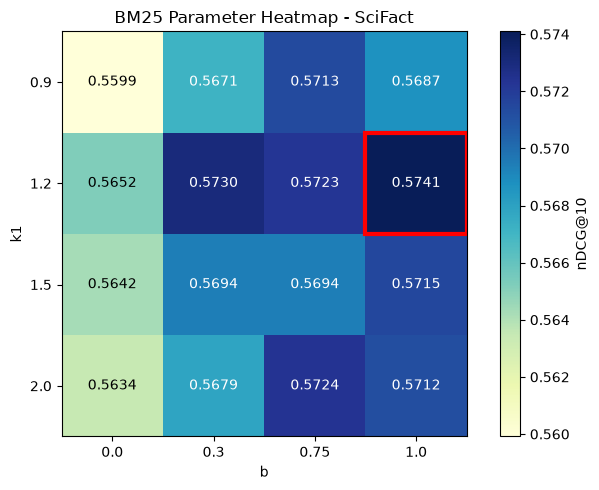

Đã lưu: d:\RAG\tep_kem\phanB\ket_qua\scifact_b4_heatmap.png


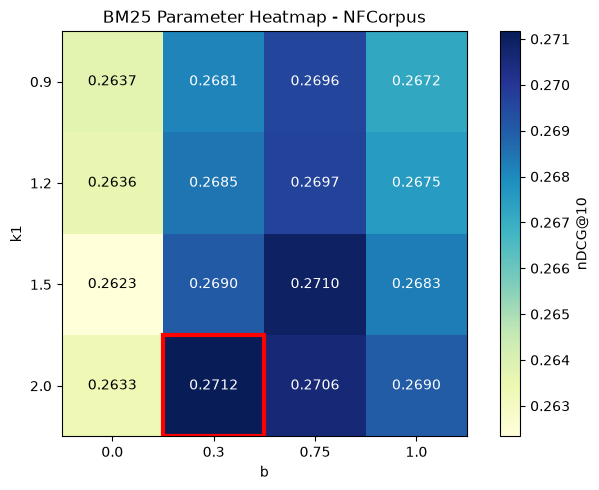

Đã lưu: d:\RAG\tep_kem\phanB\ket_qua\nfcorpus_b4_heatmap.png


In [10]:
import matplotlib.pyplot as plt
import numpy as np

OUTPUT_DIR = PROJECT_ROOT / "phanB" / "ket_qua"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def draw_heatmap(results, dataset_name):
    matrix = np.array([
        [
            next(
                row["nDCG@10"]
                for row in results
                if row["k1"] == k1 and row["b"] == b
            )
            for b in B_VALUES
        ]
        for k1 in K1_VALUES
    ])

    fig, ax = plt.subplots(figsize=(7, 5))

    im = ax.imshow(
        matrix,
        cmap="YlGnBu",
        vmin=matrix.min(),
        vmax=matrix.max()
    )
    ax.set_xticks(range(len(B_VALUES)))
    ax.set_xticklabels(B_VALUES)

    ax.set_yticks(range(len(K1_VALUES)))
    ax.set_yticklabels(K1_VALUES)

    ax.set_xlabel("b")
    ax.set_ylabel("k1")
    ax.set_title(f"BM25 Parameter Heatmap - {dataset_name}")

    best_position = np.unravel_index(np.argmax(matrix), matrix.shape)

    for i in range(len(K1_VALUES)):
        for j in range(len(B_VALUES)):
            ax.text(
                j, i,
                f"{matrix[i, j]:.4f}",
                ha="center",
                va="center",
                color="white" if matrix[i, j] > (matrix.min() + matrix.max()) / 2 else "black"
            )

    # Đánh dấu ô tốt nhất
    i, j = best_position
    ax.add_patch(
        plt.Rectangle(
            (j - 0.5, i - 0.5),
            1, 1,
            fill=False,
            edgecolor="red",
            linewidth=3
        )
    )

    fig.colorbar(im, ax=ax, label="nDCG@10")
    fig.tight_layout()

    output_path = OUTPUT_DIR / f"{dataset_name.lower()}_b4_heatmap.png"
    fig.savefig(output_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

    print(f"Đã lưu: {output_path}")


draw_heatmap(scifact_b4, "SciFact")
draw_heatmap(nfcorpus_b4, "NFCorpus")

## Nhận xét kết quả khảo sát tham số BM25

### Tập dữ liệu SciFact

- **Cấu hình tốt nhất:** `k1 = 1.2`, `b = 1.0`, đạt nDCG@10 = **0.5741**.
- **Cấu hình thấp nhất:** `k1 = 0.9`, `b = 0.0`, đạt nDCG@10 = **0.5599**.
- Khi `b = 0`, nDCG@10 nhìn chung thấp hơn các cấu hình có chuẩn hóa độ dài tài liệu.
- Khi tăng `b`, chất lượng truy xuất có xu hướng cải thiện, nhưng không tăng liên tục ở mọi giá trị `k1`.
- Thay đổi `k1` không tạo ra xu hướng tăng hoặc giảm rõ ràng.

**Kết luận:** Việc chuẩn hóa độ dài tài liệu có lợi cho SciFact. Tuy nhiên, nDCG@10 chỉ dao động từ 0.5599 đến 0.5741, cho thấy BM25 tương đối ổn định trong phạm vi tham số khảo sát.

### Tập dữ liệu NFCorpus

- **Cấu hình tốt nhất:** `k1 = 2.0`, `b = 0.3`, đạt nDCG@10 = **0.2712**.
- **Cấu hình thấp nhất:** `k1 = 1.5`, `b = 0.0`, đạt nDCG@10 = **0.2623**.
- Các cấu hình `b = 0` đều có nDCG@10 thấp, cho thấy việc không chuẩn hóa độ dài tài liệu làm giảm chất lượng truy xuất.
- Khi `b` tăng từ 0 lên 0.3 hoặc 0.75, nDCG@10 thường cải thiện.
- Khi `b = 1.0`, nDCG@10 giảm so với `b = 0.75` ở cả bốn giá trị `k1`.
- Các giá trị `k1` lớn hơn có thể mang lại kết quả tốt hơn khi kết hợp với `b` phù hợp, nhưng xu hướng không hoàn toàn tuyến tính.

**Kết luận:** NFCorpus phù hợp hơn với mức chuẩn hóa độ dài vừa phải (`b = 0.3–0.75`). nDCG@10 dao động từ 0.2623 đến 0.2712, cho thấy mức biến động tương đối nhỏ.

### So sánh và kết luận chung

| Dataset | k1 tốt nhất | b tốt nhất | nDCG@10 cao nhất |
|---|---:|---:|---:|
| SciFact | 1.2 | 1.0 | 0.5741 |
| NFCorpus | 2.0 | 0.3 | 0.2712 |

- Hai tập dữ liệu có cấu hình tham số tốt nhất khác nhau.
- Cả hai đều cho kết quả thấp khi `b = 0`, cho thấy chuẩn hóa độ dài tài liệu đóng vai trò quan trọng.
- Ảnh hưởng của `b` thể hiện rõ hơn so với `k1` trong phạm vi khảo sát.
- Không có một cấu hình `k1`, `b` nào đạt kết quả tốt nhất trên cả hai tập dữ liệu.

**Kết luận chung:** Chất lượng BM25 phụ thuộc vào đặc điểm của tập dữ liệu và cách lựa chọn tham số. Tuy nhiên, mức chênh lệch nDCG@10 giữa các cấu hình khá nhỏ, cho thấy BM25 tương đối ổn định trong phạm vi 16 tổ hợp được khảo sát.